In [1]:
!pip install opencv-python-headless==4.5.3.56
!pip install pandas==1.4.4
!pip install numpy==1.19.4
!pip install tqdm
!pip install scikit-learn==0.24.2
!pip install Pillow==8.0.1
!pip install matplotlib==3.3.4
!pip install tensorflow==2.4.0
!pip install kneed
!pip install numpy==1.19.5

     |████████████████████████████████| 37.1 MB 2.2 MB/s eta 0:00:01
You should consider upgrading via the '/usr/bin/python -m pip install --upgrade pip' command.
     |████████████████████████████████| 11.7 MB 2.2 MB/s eta 0:00:01
     |████████████████████████████████| 510 kB 57.3 MB/s eta 0:00:01
You should consider upgrading via the '/usr/bin/python -m pip install --upgrade pip' command.
You should consider upgrading via the '/usr/bin/python -m pip install --upgrade pip' command.
You should consider upgrading via the '/usr/bin/python -m pip install --upgrade pip' command.
     |████████████████████████████████| 24.9 MB 32 kB/s  eta 0:00:01
     |████████████████████████████████| 301 kB 67.8 MB/s eta 0:00:01
You should consider upgrading via the '/usr/bin/python -m pip install --upgrade pip' command.
     |████████████████████████████████| 2.2 MB 2.9 MB/s eta 0:00:01
You should consider upgrading via the '/usr/bin/python -m pip install --upgrade pip' command.
     |█████████████████

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tqdm
import tensorflow as tf
from PIL import Image
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical
data=pd.read_csv("data.csv")
labels=[]
links=[]
for idx,row in tqdm.tqdm(data.iterrows()):
    labels.append(row['labels'])
    links.append(row['path'])

13320it [00:00, 14090.75it/s]


In [3]:
import tensorflow as tf
from tensorflow.keras.layers import (
    Input,
    TimeDistributed,
    GlobalAveragePooling2D,
    Bidirectional,
    GRU,
    Dense,
    Dropout
)
from tensorflow.keras.models import Model
from tensorflow.keras.applications import EfficientNetB3


def build_videonet(
        image_size=(224,224),
        num_classes=101,
        train_backbone=False):

    ##########################################################
    # Variable number of keyframes
    ##########################################################
    inputs = Input(
        shape=(None,
               image_size[0],
               image_size[1],
               3),
        name="video_frames"
    )

    ##########################################################
    # EfficientNetB3
    ##########################################################
    backbone = EfficientNetB3(
        include_top=False,
        weights='imagenet',
        input_shape=(224,224,3)
    )

    backbone.trainable = train_backbone

    ##########################################################
    # Spatial Feature Extraction
    ##########################################################
    x = TimeDistributed(backbone)(inputs)

    x = TimeDistributed(
        GlobalAveragePooling2D()
    )(x)

    ##########################################################
    # Temporal Modeling
    ##########################################################
    x = Bidirectional(
            GRU(
                128,
                return_sequences=True,
                dropout=0.3
            )
        )(x)

    x = Bidirectional(
            GRU(
                64,
                return_sequences=False,
                dropout=0.3
            )
        )(x)

    ##########################################################
    # Video Representation
    ##########################################################
    video_feature = Dense(
        128,
        activation='relu',
        name='video_feature'
    )(x)

    x = Dropout(0.5)(video_feature)

    ##########################################################
    # Classification
    ##########################################################
    outputs = Dense(
        num_classes,
        activation='softmax',
        name='classification'
    )(x)

    model = Model(inputs, outputs)

    return model


model = build_videonet()

model.summary()

43941888/43941136 [==============================] - 4s 0us/step
Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
video_frames (InputLayer)    [(None, None, 224, 224, 3 0         
_________________________________________________________________
time_distributed (TimeDistri (None, None, 7, 7, 1536)  10783535  
_________________________________________________________________
time_distributed_1 (TimeDist (None, None, 1536)        0         
_________________________________________________________________
bidirectional (Bidirectional (None, None, 256)         1279488   
_________________________________________________________________
bidirectional_1 (Bidirection (None, 128)               123648    
_________________________________________________________________
video_feature (Dense)        (None, 128)               16512     
______________________________________________________________

In [4]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(1e-4),

    loss='categorical_crossentropy',

    metrics=['accuracy']

)

In [3]:
import os
import numpy as np
from sklearn.model_selection import train_test_split

# Assuming you have a list of labels named 'labels' and the number of folders is 13320
#labels = [...]  # Your list of labels
num_folders = len(labels)  # Total number of folders

# Generate a list of folder numbers
video_folders = list(range(0, num_folders))

# Split the data into train and test sets while maintaining class distribution

train_videos, test_videos, train_labels, test_labels = train_test_split(

    video_folders,

    labels,

    test_size=0.20,

    random_state=42,

    stratify=labels

)

train_videos, val_videos, train_labels, val_labels = train_test_split(

    train_videos,

    train_labels,

    test_size=0.125,

    random_state=42,

    stratify=train_labels

)
# Now you have the list of folder numbers and labels for train and test sets
print(len(train_videos))

print(len(val_videos))

print(len(test_videos))


9324
1332
2664


In [4]:
from PIL import Image
import os
import numpy as np
import tqdm

def load_and_preprocess_videos(video_folders,
                               video_labels,
                               img_size=(224,224),
                               data_dir="keyframes"):

    videos = []
    labels = []

    new_width, new_height = img_size

    for folder, label in tqdm.tqdm(zip(video_folders, video_labels),
                                   total=len(video_folders)):

        folder_path = os.path.join(data_dir, str(folder))

        if not os.path.isdir(folder_path):
            continue

        frame_files = sorted([
            f for f in os.listdir(folder_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        frames = []

        for frame in frame_files:

            img = Image.open(os.path.join(folder_path, frame)).convert("RGB")
            img = img.resize((new_width, new_height))

            img = np.array(img, dtype=np.float32) / 255.0

            frames.append(img)

        if len(frames) > 0:
            videos.append(np.array(frames))
            labels.append(label)

    return videos, np.array(labels)

In [4]:
from PIL import Image
import os
import numpy as np
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor
import multiprocessing


def load_and_preprocess_videos(video_folders,
                               video_labels,
                               img_size=(224,224),
                               data_dir="keyframes",
                               num_workers=None):

    if num_workers is None:
        num_workers = multiprocessing.cpu_count()

    new_width, new_height = img_size

    def process_video(args):
        folder, label = args

        folder_path = os.path.join(data_dir, str(folder))

        if not os.path.isdir(folder_path):
            return None

        frame_files = sorted([
            f for f in os.listdir(folder_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

        frames = []

        for frame in frame_files:
            img = Image.open(os.path.join(folder_path, frame)).convert("RGB")
            img = img.resize((new_width, new_height))
            img = np.asarray(img, dtype=np.float32) / 255.0
            frames.append(img)

        if len(frames) == 0:
            return None

        return np.asarray(frames), label

    videos = []
    labels = []

    with ThreadPoolExecutor(max_workers=num_workers) as executor:

        results = executor.map(
            process_video,
            zip(video_folders, video_labels)
        )

        for result in tqdm(results,
                           total=len(video_folders),
                           desc="Loading videos"):

            if result is None:
                continue

            frames, label = result
            videos.append(frames)
            labels.append(label)

    return videos, np.array(labels)

In [5]:
import numpy as np
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

def preprocess_labels_and_data(train_labels_final):
    # Convert labels to numerical values using LabelEncoder
    label_encoder = LabelEncoder()
    label_encoder.fit(np.unique(train_labels_final).tolist())
    encoded_labels = label_encoder.transform(train_labels_final)

    # Preprocess the keyframes
    #train_data = np.array(train_data, dtype=np.float32) / 255.0  # Normalize the pixel values between 0 and 1

    # Convert labels to one-hot encoded vectors
    train_labels_preprocessed = to_categorical(encoded_labels)
    
    return train_labels_preprocessed

In [ ]:
X_train, y_train = load_and_preprocess_videos(

    train_videos,

    train_labels,

    img_size=(224,224),

    data_dir="keyframes"

)

X_val, y_val = load_and_preprocess_videos(

    val_videos,

    val_labels,

    img_size=(224,224),

    data_dir="keyframes"

)

 14%|█▎        | 1264/9324 [42:02<11:12:12,  5.00s/it]

In [ ]:
y_train = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)

y_val   = tf.keras.utils.to_categorical(y_val, NUM_CLASSES)

In [ ]:
def generator(videos, labels):

    for video, label in zip(videos, labels):
        yield video, label

In [ ]:
output_signature = (
    tf.TensorSpec(shape=(None,224,224,3), dtype=tf.float32),
    tf.TensorSpec(shape=(NUM_CLASSES,), dtype=tf.float32)
)

train_ds = tf.data.Dataset.from_generator(
    lambda: generator(X_train, y_train),
    output_signature=output_signature
)

val_ds = tf.data.Dataset.from_generator(
    lambda: generator(X_val, y_val),
    output_signature=output_signature
)

In [ ]:
BATCH_SIZE = 8

train_ds = train_ds.padded_batch(
    BATCH_SIZE,
    padded_shapes=(
        [None,224,224,3],
        [NUM_CLASSES]
    ),
    padding_values=(
        0.0,
        0.0
    )
).prefetch(tf.data.AUTOTUNE)

val_ds = val_ds.padded_batch(
    BATCH_SIZE,
    padded_shapes=(
        [None,224,224,3],
        [NUM_CLASSES]
    ),
    padding_values=(
        0.0,
        0.0
    )
).prefetch(tf.data.AUTOTUNE)

In [ ]:
callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        "videonet.keras",
        save_best_only=True,
        monitor="val_accuracy"
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    )
]

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks
)

In [5]:
import os
import cv2
import numpy as np
import tqdm


def preprocess_and_save_videos(
        keyframes_dir="keyframes",
        output_dir="processed_videos",
        img_size=(224, 224),
        overwrite=False):

    os.makedirs(output_dir, exist_ok=True)

    width, height = img_size

    # Read all video folders and sort numerically
    video_folders = sorted(
        [f for f in os.listdir(keyframes_dir)
         if os.path.isdir(os.path.join(keyframes_dir, f))],
        key=lambda x: int(x)
    )

    for video_idx in tqdm.tqdm(video_folders, desc="Processing videos"):

        folder_path = os.path.join(keyframes_dir, video_idx)

        output_file = os.path.join(output_dir, f"{video_idx}_video.npy")

        if os.path.exists(output_file) and not overwrite:
            continue

        frame_files = sorted(
            [f for f in os.listdir(folder_path)
             if f.lower().endswith((".jpg", ".jpeg", ".png"))],
            key=lambda x: int(os.path.splitext(x)[0])
        )

        frames = []

        for frame in frame_files:

            img = cv2.imread(os.path.join(folder_path, frame))

            if img is None:
                continue

            # Keep BGR if that's what you want.
            # If using ImageNet pretrained models, uncomment the next line.
            # img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            img = cv2.resize(
                img,
                (width, height),
                interpolation=cv2.INTER_AREA
            )

            img = img.astype(np.float32) / 255.0

            frames.append(img)

        if len(frames) == 0:
            print(f"Skipping {video_idx}: no frames found.")
            continue

        video = np.stack(frames, axis=0)

        # Shape: (num_frames, H, W, 3)
        np.save(output_file, video)

    print("Finished preprocessing all videos.")

In [7]:
preprocess_and_save_videos(
    keyframes_dir="keyframes",
    output_dir="processed_videos",
    img_size=(224, 224)
)

Processing videos:   9%|▉         | 1205/13320 [02:00<07:35, 26.58it/s] 

Skipping 1204: no frames found.
Skipping 1208: no frames found.


Processing videos:  14%|█▍        | 1894/13320 [03:32<08:20, 22.82it/s]  

Skipping 1892: no frames found.


Processing videos:  22%|██▏       | 2928/13320 [05:57<07:19, 23.67it/s]  

Skipping 2925: no frames found.
Skipping 2926: no frames found.


... (14 outputs left out)

Processing videos:  97%|█████████▋| 12899/13320 [33:08<00:50,  8.40it/s]  

Skipping 12898: no frames found.


Processing videos: 100%|██████████| 13320/13320 [33:56<00:00,  6.54it/s]

Finished preprocessing all videos.


In [31]:
import os

empty = []

for folder in sorted(os.listdir("keyframes"), key=int):

    path = os.path.join("keyframes", folder)

    if os.path.isdir(path):

        imgs = [f for f in os.listdir(path)
                if f.lower().endswith((".jpg",".jpeg",".png"))]

        if len(imgs) == 0:
            empty.append(folder)

print("Empty folders:", len(empty))
print(empty)

Empty folders: 4
['2925', '3443', '4324', '4325']


In [32]:
links[int(empty[0])]

'/workspace/data/data/UCF-101/CliffDiving/v_CliffDiving_g22_c02.avi'

In [18]:
import cv2
import numpy as np
from scipy.stats import entropy

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array

###############################################################
# Load pretrained ResNet50
###############################################################

base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    pooling='avg'
)

###############################################################
# Feature Extraction
###############################################################

def extract_feature(frame):

    image = cv2.resize(frame, (224,224))
    image = img_to_array(image)
    image = np.expand_dims(image, axis=0)
    image = preprocess_input(image)

    feature = base_model.predict(image, verbose=0)[0]

    return feature

###############################################################
# Shannon Entropy
###############################################################

def frame_entropy(frame):

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    hist = cv2.calcHist(
        [gray],
        [0],
        None,
        [256],
        [0,256]
    )

    hist = hist.ravel()

    hist /= hist.sum()

    return entropy(hist, base=2)

###############################################################
# Main Function
###############################################################

def extract_keyframes(video_path,
                      z_threshold=1.0):

    cap = cv2.VideoCapture(video_path)

    frames = []

    entropies = []

    features = []

    while True:

        ret, frame = cap.read()

        if not ret:
            break

        frames.append(frame)

        entropies.append(
            frame_entropy(frame)
        )

        features.append(
            extract_feature(frame)
        )

    cap.release()

    entropies = np.array(entropies)

    ###########################################################
    # Feature Difference
    ###########################################################

    feature_diff = [0]

    for i in range(1, len(features)):

        d = np.linalg.norm(
            features[i]-features[i-1]
        )

        feature_diff.append(d)

    feature_diff = np.array(feature_diff)

    ###########################################################
    # Normalize
    ###########################################################

    H = (entropies-entropies.min()) / \
        (entropies.max()-entropies.min()+1e-8)

    D = (feature_diff-feature_diff.min()) / \
        (feature_diff.max()-feature_diff.min()+1e-8)

    ###########################################################
    # Adaptive alpha beta
    ###########################################################

    sigma_H = np.std(H)

    sigma_D = np.std(D)

    alpha = sigma_H / (sigma_H + sigma_D + 1e-8)

    beta = sigma_D / (sigma_H + sigma_D + 1e-8)

    ###########################################################
    # Frame Importance Score
    ###########################################################

    score = alpha*H + beta*D

    ###########################################################
    # Z-score
    ###########################################################

    mean = np.mean(score)

    std = np.std(score)

    z = (score-mean)/(std+1e-8)

    ###########################################################
    # Keyframes
    ###########################################################

    keyframes = []

    keyframe_indices = []

    for i in range(len(frames)):

        if z[i] > z_threshold:

            keyframes.append(frames[i])

            keyframe_indices.append(i)

    return keyframes,\
           keyframe_indices,\
           score,\
           z,\
           alpha,\
           beta

94773248/94765736 [==============================] - 7s 0us/step


In [33]:
for emp in empty:
    keyframes, indices, score, z, alpha, beta = extract_keyframes(
    links[int(emp)],
    z_threshold=1.0
  )

    print("Alpha :", alpha)
    print("Beta  :", beta)
    print("Number of keyframes :", len(indices))
    print(indices)
    # Create folder for this video's keyframes
    video_folder = os.path.join("keyframes", str(int(emp)))
    os.makedirs(video_folder, exist_ok=True)

    # Save keyframes as 1.jpg, 2.jpg, ...
    for i, frame in enumerate(keyframes, start=1):
        save_path = os.path.join(video_folder, f"{i}.jpg")
        cv2.imwrite(save_path, frame)

Alpha : 0.6813048737945415
Beta  : 0.3186951071383012
Number of keyframes : 0
[]
Alpha : 0.7515267579062054
Beta  : 0.24847321845776796
Number of keyframes : 0
[]
Alpha : 0.796322178608126
Beta  : 0.20367779838572214
Number of keyframes : 0
[]
Alpha : 0.7657672604851291
Beta  : 0.23423271682031996
Number of keyframes : 0
[]


In [38]:
empty

['2925', '3443', '4324', '4325']

In [39]:
for emp in empty:
    frames=[]
    keyframes=[] 
    print(links[int(emp)])
    cap = cv2.VideoCapture(links[int(emp)])
    while True:

        ret, frame = cap.read()

        if not ret:
            break
        frames.append(frame)
    n=len(frames)
    for i in range(1,n,10):
      keyframes.append(frames[i])
   
    video_folder = os.path.join("keyframes", str(int(emp)))
    os.makedirs(video_folder, exist_ok=True)

    # Save keyframes as 1.jpg, 2.jpg, ...
    for i, frame in enumerate(keyframes, start=1):
        save_path = os.path.join(video_folder, f"{i}.jpg")
        cv2.imwrite(save_path, frame)

/workspace/data/data/UCF-101/CliffDiving/v_CliffDiving_g22_c02.avi
/workspace/data/data/UCF-101/Diving/v_Diving_g13_c06.avi
/workspace/data/data/UCF-101/GolfSwing/v_GolfSwing_g05_c06.avi
/workspace/data/data/UCF-101/GolfSwing/v_GolfSwing_g05_c07.avi


In [ ]:
import os
import cv2

# Create the main output folder
output_dir = "keyframes"
os.makedirs(output_dir, exist_ok=True)

for video_num, link in enumerate(links, start=1):

    keyframes, indices, score, z, alpha, beta = extract_keyframes(
        link,
        z_threshold=1.0
    )

    print(f"Video {video_num}")
    print("Alpha :", alpha)
    print("Beta  :", beta)
    print("Number of keyframes :", len(indices))
    print(indices)

    # Create folder for this video's keyframes
    video_folder = os.path.join(output_dir, str(video_num))
    os.makedirs(video_folder, exist_ok=True)

    # Save keyframes as 1.jpg, 2.jpg, ...
    for i, frame in enumerate(keyframes, start=1):
        save_path = os.path.join(video_folder, f"{i}.jpg")
        cv2.imwrite(save_path, frame)

print("All keyframes saved successfully.")

In [40]:
  for video_idx in empty:

        folder_path = os.path.join("keyframes", video_idx)

        output_file = os.path.join("processed_videos", f"{video_idx}_video.npy")

        if os.path.exists(output_file) and not overwrite:
            continue

        frame_files = sorted(
            [f for f in os.listdir(folder_path)
             if f.lower().endswith((".jpg", ".jpeg", ".png"))],
            key=lambda x: int(os.path.splitext(x)[0])
        )

        frames = []

        for frame in frame_files:

            img = cv2.imread(os.path.join(folder_path, frame))

            if img is None:
                continue

            # Keep BGR if that's what you want.
            # If using ImageNet pretrained models, uncomment the next line.
            # img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            img = cv2.resize(
                img,
                (224, 224),
                interpolation=cv2.INTER_AREA
            )

            img = img.astype(np.float32) / 255.0

            frames.append(img)

        if len(frames) == 0:
            print(f"Skipping {video_idx}: no frames found.")
            continue

        video = np.stack(frames, axis=0)

        # Shape: (num_frames, H, W, 3)
        np.save(output_file, video)


In [19]:
import os
import numpy as np
import tqdm

def load_processed_videos(processed_dir="processed_videos"):

    npy_files = sorted(
        [f for f in os.listdir(processed_dir) if f.endswith(".npy")],
        key=lambda x: int(x.split("_")[0])
    )

    videos = []

    for file in tqdm.tqdm(npy_files, desc="Loading videos"):
        video = np.load(os.path.join(processed_dir, file))
        videos.append(video)

    X = np.stack(videos, axis=0)

    return X

In [9]:
X_train = load_processed_videos("processed_videos")

print(X_train.shape)

Loading videos: 100%|██████████| 13304/13304 [04:08<00:00, 53.64it/s] 


ValueError: all input arrays must have the same shape

In [41]:
import os

processed_dir = "processed_videos"

processed_files = sorted(
    [f for f in os.listdir(processed_dir) if f.endswith(".npy")],
    key=lambda x: int(x.split("_")[0])
)

print("Processed videos:", len(processed_files))

Processed videos: 13320


In [60]:
import pandas as pd
#df1 = pd.read_csv("D:/dgxuser36/data/Hassan_videoNet/precision_recall_gru_weighted.csv")
df1 = pd.read_csv("D:/dgxuser36/data/UCFcodes/UCFcodes/4th paper/precision_recall.csv")
precision = df1["precision"].values
recall = df1["recall"].values


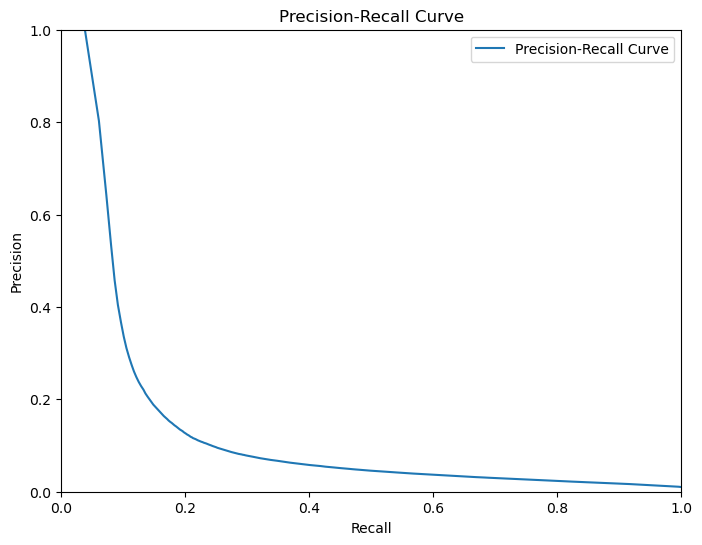

In [62]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt
# Plot the Precision-Recall curve
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, label='Precision-Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
#plt.savefig('randomresnet50results/precission_recallcurve.png')
#plt.savefig('precission_recallcurve.png')
plt.axis([0, 1, 0, 1])
plt.legend()
plt.show()

In [19]:
!cd

D:\dgxuser36\data\Hassan_videoNet


ValueError: '..' is not a valid value for ls; supported values are '-', '--', '-.', ':', 'None', ' ', '', 'solid', 'dashed', 'dashdot', 'dotted'

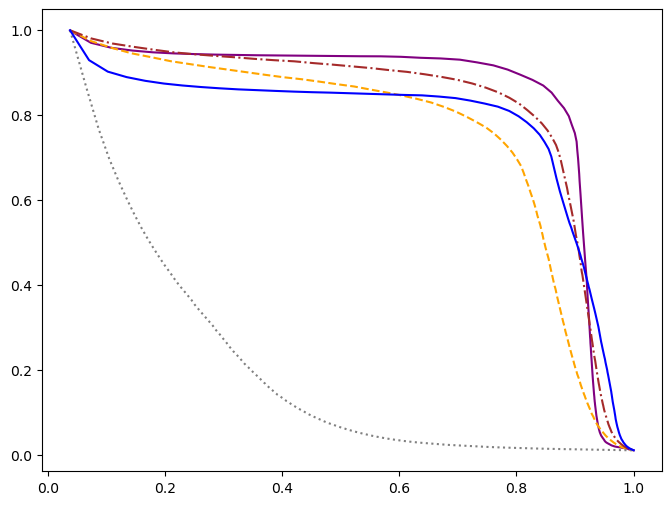

In [64]:
# Comparison with existing models using custom styles
import matplotlib.pyplot as plt
import pandas as pd

# File paths updated for Windows base directory: D:/dgxuser36/data
file_paths = [
    "precision_recall_gru_weighted.csv",
    "D:/dgxuser36/data/UCFcodes/UCFcodes/3D CNN_HASSAN/precision_recall.csv",
    "D:/dgxuser36/data/UCFcodes/UCFcodes/3D CNN_HASSAN/R(2+1)/precision_recall.csv",
    "D:/dgxuser36/data/UCFcodes/UCFcodes/2nd paper/ResNet50/precission_recall.csv",
    "D:/dgxuser36/data//UCFcodes/UCFcodes/2nd paper/Dwtcomparitive/precission_recall.csv",
    "D:/dgxuser36/data/UCFcodes/UCFcodes/4th paper/precision_recall.csv"
    
]

# Labels for the methods
labels = ["Proposed","R3D", "R(2+1)D", "ResNet50", "DWT+Fuzzy","TimesFormer"]

# Define styles and colors for each method
line_styles = ['-', '--', '-.', ':', '-','..']
colors = ['purple', 'orange', 'brown', 'gray', 'blue','black']

# Initialize a figure
plt.figure(figsize=(8, 6))

# Loop through the files and plot precision-recall curves with style
for file_path, label, style, color in zip(file_paths, labels, line_styles, colors):
    # Read the CSV file
    data = pd.read_csv(file_path)
    
    # Read precision and recall values
    recall = data['recall'].values
    precision = data['precision'].values
    
    # Plot with custom linestyle and color
    plt.plot(recall, precision, label=label, linestyle=style, color=color)

# Add labels and title
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall Curve Comparison')

# Customize axis limits
plt.axis([0, 1, 0, 1])

# Show legend
plt.legend()

# Save the figure
plt.savefig("precision_recallcurve_compare.png", dpi=300)

# Display the plot
plt.show()

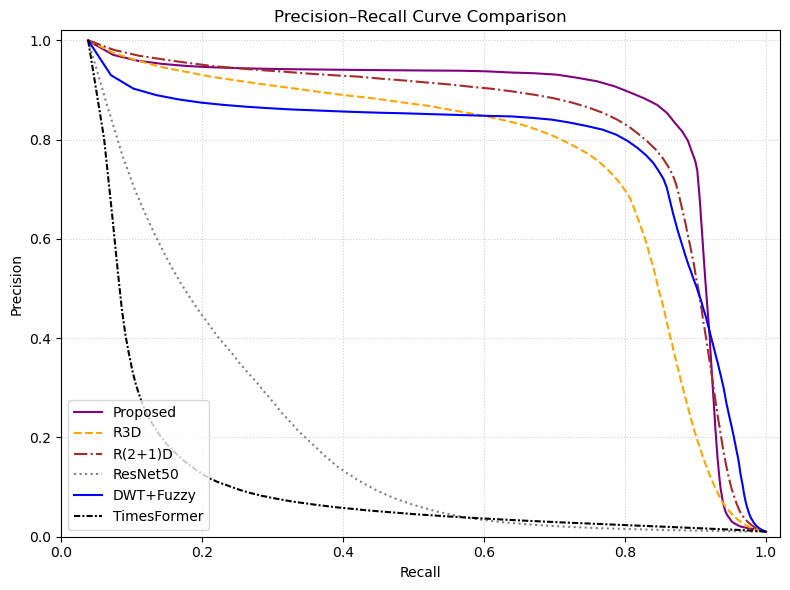

In [68]:
# Comparison with existing models using custom styles
import matplotlib.pyplot as plt
import pandas as pd

# File paths updated for Windows base directory: D:/dgxuser36/data
file_paths = [
    "precision_recall_gru_weighted.csv",
    "D:/dgxuser36/data/UCFcodes/UCFcodes/3D CNN_HASSAN/precision_recall.csv",
    "D:/dgxuser36/data/UCFcodes/UCFcodes/3D CNN_HASSAN/R(2+1)/precision_recall.csv",
    "D:/dgxuser36/data/UCFcodes/UCFcodes/2nd paper/ResNet50/precission_recall.csv",
    "D:/dgxuser36/data/UCFcodes/UCFcodes/2nd paper/Dwtcomparitive/precission_recall.csv",
    "D:/dgxuser36/data/UCFcodes/UCFcodes/4th paper/precision_recall.csv"
]

# Labels for the methods
labels = ["Proposed", "R3D", "R(2+1)D", "ResNet50", "DWT+Fuzzy", "TimesFormer"]

# Define valid styles and colors for each method
# Note: Replaced '..' with a valid dash-dot-dot style tuple
line_styles = ['-', '--', '-.', ':', '-', (0, (3, 1, 1, 1))]
colors = ['purple', 'orange', 'brown', 'gray', 'blue', 'black']

# Initialize a figure
plt.figure(figsize=(8, 6))

# Loop through the files and plot precision-recall curves with style
for file_path, label, style, color in zip(file_paths, labels, line_styles, colors):
    # Read the CSV file
    data = pd.read_csv(file_path)
    
    # Read precision and recall values
    recall = data['recall'].values
    precision = data['precision'].values
    
    # Plot with custom linestyle and color
    plt.plot(recall, precision, label=label, linestyle=style, color=color)

# Add labels and title
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision–Recall Curve Comparison')

# Set axis limits with slight margin so lines on edges (0 or 1) aren't clipped
plt.xlim([0, 1.02])
plt.ylim([0, 1.02])

# Show grid and legend
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower left')

# Save and display
plt.tight_layout()
plt.savefig("precision_recallcurve_compare.png", dpi=300)
plt.show()

In [74]:
data=pd.read_csv("D:/dgxuser36/data/UCFcodes/UCFcodes/2nd paper/Dwtcomparitive/precission_recall.csv")

In [86]:
# Specify the row indices you want to print
row_indices = [1, 5, 10, 15, 25, 50, 100]

# Print the rows
print(data.iloc[row_indices])

     precision    recall  f1_score       auc
1     0.929617  0.070338  0.130780  0.030142
5     0.874437  0.198117  0.323043  0.027793
10    0.858825  0.356534  0.503884  0.027215
15    0.851633  0.514092  0.641151  0.026686
25    0.809872  0.787560  0.798560  0.015681
50    0.479215  0.907015  0.627104  0.000986
100   0.252401  0.946535  0.398531  0.000110


In [ ]:
#ablation
#UCFcodes/UCFcodes/3D CNN_HASSAN/Experimentations/EfficientNet/precision_recall.csv

In [108]:
#data=pd.read_csv("feature_spatial_gru.csv")import numpy as np

def calculate_precision_and_recall(distance_matrix, feature_test, clst):
    num_samples = feature_test.shape[0]

    # Step 1: Sort indices by distance
    sorted_indices = np.argsort(distance_matrix, axis=1)
    sorted_labels = clst[sorted_indices]

    # Step 2: Precompute class counts
    unique_labels, counts = np.unique(clst, return_counts=True)
    label_count_dict = {label: count for label, count in zip(unique_labels, counts)}

    # Step 3: Initialize matrices
    precision = np.empty((num_samples, num_samples))
    recall = np.empty((num_samples, num_samples))

    # Step 4: Loop with progress bar
    for i in range(num_samples):
        true_positives = 0
        correct_label = clst[i]
        for j in range(num_samples):
            if sorted_labels[i][j] == correct_label:
                true_positives += 1
            precision[i][j] = true_positives / (j + 1)
            recall[i][j] = true_positives / label_count_dict[correct_label]

    mean_precision = np.mean(precision, axis=0)
    mean_recall = np.mean(recall, axis=0)

    return mean_precision, mean_recall

In [112]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import pairwise_distances

def calculate_f1_and_auc(filepath):
    # Load data with specified column names
    data = pd.read_csv(filepath, header=0)
    
    cols = {c.lower(): c for c in data.columns}
    p_col = cols.get('precision', 'Precision')
    r_col = cols.get('recall', 'Recall')

    # Calculate F1 score for each row (with safety check for division by zero)
    denominator = data[p_col] + data[r_col]
    data['f1_score'] = np.where(denominator == 0, 0, 2 * (data[p_col] * data[r_col]) / denominator)
    
    # Initialize AUC values with the first value
    auc_values = [data[r_col][0] * data[p_col][0]]
    
    # Loop through each pair of points and apply the step rule
    for i in range(1, len(data)):
        recall_diff = data[r_col][i] - data[r_col][i - 1]
        auc = recall_diff * data[p_col][i]
        auc_values.append(auc)
    
    # Add the cumulative AUC values to the DataFrame
    data['auc'] = auc_values
    
    # Save the modified data back to the CSV with updated standard header names
    data.to_csv(filepath, index=False, header=["precision", "recall", "f1_score", "auc"])
    
    print("Data with F1 scores and AUC values saved successfully!")
    print(data.head())
    
    return data

# --- Main Pipeline ---

# 1. Load feature data from your CSV file
csv_input_path = "feature_spatial_gru.csv"
print(f"Loading data from {csv_input_path}...")
df_test = pd.read_csv(csv_input_path)

# Extract features (all columns except the last) and labels (last column)
# Each row represents a single video directly
feature_test = df_test.iloc[:, :-1].values
labels_test = df_test.iloc[:, -1].values

# 2. Encode labels (Pure numpy/scikit-learn one-hot encoding)
label_encoder = LabelEncoder()
encoded_labels = label_encoder.fit_transform(labels_test)
num_classes = len(np.unique(encoded_labels))
labels_one_hot = np.eye(num_classes)[encoded_labels]

clst = np.argmax(labels_one_hot, axis=1) + 1

# 3. Calculate Euclidean distance matrix directly from features
print("Calculating distance matrix...")
distance_matrix = pairwise_distances(feature_test, metric='euclidean')

# 4. Calculate precision and recall 
print("Calculating precision and recall...")
precision, recall = calculate_precision_and_recall(distance_matrix, feature_test, clst)

# 5. Save raw precision and recall to CSV first
csv_output_path = 'precision_recall_gru.csv'
pd.DataFrame({'precision': precision, 'recall': recall}).to_csv(csv_output_path, index=False)

# 6. Calculate F1 & AUC from the CSV and update it
updated_data = calculate_f1_and_auc(csv_output_path)

# 7. Plot precision-recall curve (if plotting function is available)
try:
    plot_precision_recall_curve(precision, recall)
except NameError:
    print("`plot_precision_recall_curve` function not found in scope, skipping plot generation.")

Loading data from feature_spatial_gru.csv...
Calculating distance matrix...
Calculating precision and recall...
Data with F1 scores and AUC values saved successfully!
   precision    recall  f1_score       auc
0   1.000000  0.037913  0.073056  0.037913
1   0.969970  0.073485  0.136621  0.034504
2   0.954830  0.108440  0.194760  0.033375
3   0.946227  0.143213  0.248774  0.032904
4   0.940841  0.177948  0.299290  0.032680
`plot_precision_recall_curve` function not found in scope, skipping plot generation.


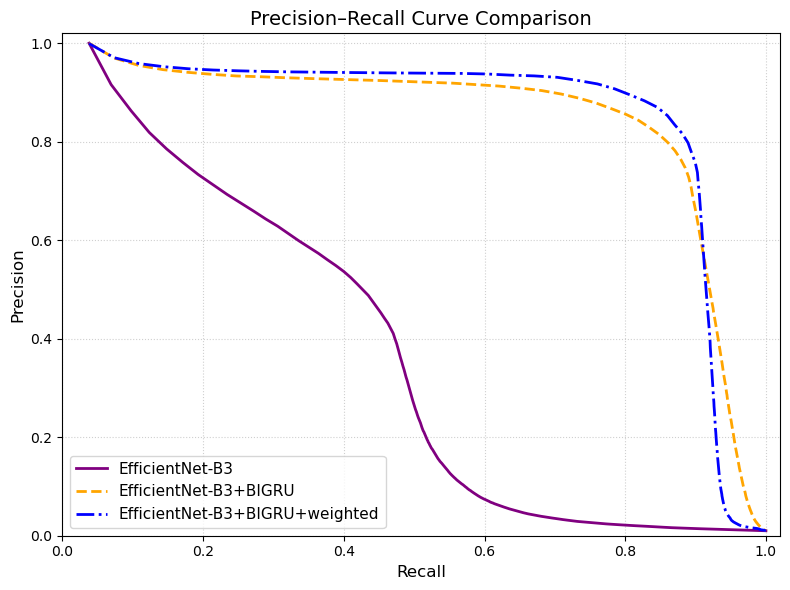

In [125]:
import matplotlib.pyplot as plt
import pandas as pd

# File paths for your specific models
file_paths = [
    "D:/dgxuser36/data/UCFcodes/UCFcodes/3D CNN_HASSAN/Experimentations/EfficientNet/precision_recall.csv"
     ,"precision_recall_gru.csv",
    "precision_recall_gru_weighted.csv"
     
   ]

# Labels matching the files
labels = ["EfficientNet-B3","EfficientNet-B3+BIGRU", "EfficientNet-B3+BIGRU+weighted",]

# Define distinct line styles and colors
line_styles = ['-', '--', '-.']
colors = ['purple', 'orange', 'blue']

# Initialize a figure
plt.figure(figsize=(8, 6))

# Loop through the files and plot precision-recall curves with style
for file_path, label, style, color in zip(file_paths, labels, line_styles, colors):
    # Read the CSV file
    data = pd.read_csv(file_path)
    
    # Read precision and recall values (handling column name case variations just in case)
    cols = {c.lower(): c for c in data.columns}
    r_col = cols.get('recall', 'Recall')
    p_col = cols.get('precision', 'Precision')
    
    recall = data[r_col].values
    precision = data[p_col].values
    
    # Plot with custom linestyle and color
    plt.plot(recall, precision, label=label, linestyle=style, color=color, linewidth=2)

# Add labels and title
plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision–Recall Curve Comparison', fontsize=14)

# Set axis limits with slight margin so lines on edges aren't clipped
plt.xlim([0, 1.02])
plt.ylim([0, 1.02])

# Show grid and legend
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower left', fontsize=11)

# Save and display
plt.tight_layout()
plt.savefig("precision_recallcurve_compare_gru_effnet.png", dpi=300)
plt.show()

In [140]:
import pandas as pd

# File paths for your models
file_paths = [
    "D:/dgxuser36/data/UCFcodes/UCFcodes/3D CNN_HASSAN/Experimentations/EfficientNet/precision_recall.csv"
     ,"precision_recall_gru.csv",
    "precision_recall_gru_weighted.csv"
     
   ]

# Labels matching the files
model_names = ["EfficientNet-B3","EfficientNet-B3+BIGRU", "EfficientNet-B3+BIGRU+weighted",]


# Desired 1-based/0-based row indices to inspect
# Note: Using 0-based integer indexing. If your rows correspond to spreadsheet line numbers, adjust as needed.
row_indices = [1, 4, 9, 24, 49, 99]

summary_rows = []
auc_sums = {}

for path, model_name in zip(file_paths, model_names):
    try:
        # Read the CSV file
        df = pd.read_csv(path)
        
        # Normalize column names to lowercase to prevent KeyErrors
        df.columns = [c.lower() for c in df.columns]
        
        # 1. Extract specified rows (ensure indices don't exceed dataframe length)
        valid_indices = [i for i in row_indices if i < len(df)]
        subset = df.iloc[valid_indices].copy()
        subset.insert(0, 'Model', model_name)
        subset.insert(1, 'Row_Index', valid_indices)
        
        summary_rows.append(subset)
        
        # 2. Calculate the sum of the entire 'auc' column
        if 'auc' in df.columns:
            total_auc = df['auc'].sum()
            auc_sums[model_name] = total_auc
        else:
            auc_sums[model_name] = "AUC column not found"
            
    except FileNotFoundError:
        print(f"Warning: File not found -> {path}")
    except Exception as e:
        print(f"Error processing {path}: {e}")

# Combine all subsets into a single comparison table
if summary_rows:
    comparison_table = pd.concat(summary_rows, ignore_index=True)
    
    print("=" * 70)
    print("TOP ROWS COMPARISON TABLE (Rows: 2, 5, 25, 50, 100)")
    print("=" * 70)
    print(comparison_table.to_string(index=False))
    print("\n" + "=" * 70)
    
    # Display total AUC sums
    print("TOTAL SUM OF THE ENTIRE 'AUC' COLUMN PER MODEL:")
    print("=" * 70)
    for model, total_val in auc_sums.items():
        if isinstance(total_val, (int, float)):
            print(f"  - {model}: {total_val:.4f}")
        else:
            print(f"  - {model}: {total_val}")
    print("=" * 70)
    
    # Optionally save the comparison table to a new CSV
    comparison_table.to_csv("model_comparison_top_rows.csv", index=False)
    print("\nComparison table saved to 'model_comparison_top_rows.csv'")

TOP ROWS COMPARISON TABLE (Rows: 2, 5, 25, 50, 100)
                         Model  Row_Index  precision   recall  f1_score      auc
               EfficientNet-B3          1   0.915916 0.069264  0.128789 0.028715
               EfficientNet-B3          4   0.785511 0.147980  0.249043 0.019222
               EfficientNet-B3          9   0.675563 0.253418  0.368575 0.013065
               EfficientNet-B3         24   0.475586 0.440982  0.457630 0.002941
               EfficientNet-B3         49   0.269970 0.498917  0.350357 0.000286
               EfficientNet-B3         99   0.145788 0.539937  0.229586 0.000102
         EfficientNet-B3+BIGRU          1   0.969970 0.073485  0.136621 0.034504
         EfficientNet-B3+BIGRU          4   0.940841 0.177948  0.299290 0.032680
         EfficientNet-B3+BIGRU          9   0.928303 0.350877  0.509265 0.032040
         EfficientNet-B3+BIGRU         24   0.855871 0.800554  0.827289 0.017606
         EfficientNet-B3+BIGRU         49   0.496396 0.92